# Forest Proximity Tutorial (RF, ExtraTrees, RotationForest, IsolationForest)

This notebook demonstrates how to generate forest-based proximities using `forestgap`, embed them with PHATE, and compare embeddings across model families.

Workflow:
1. Set `TASK_TYPE` to `classification` or `regression` (single switch at top).
2. Load dataset and split train/test.
3. Build proximities for each forest model.
4. Compute PHATE embedding from each model's proximity matrix.
5. Compare all embeddings in one final subplot figure.

In [1]:
from pathlib import Path
import sys

# Add parent directory to path to import local forestgap package
sys.path.insert(0, str(Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import sparse
import warnings

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import LabelEncoder, OneHotEncoder
from sklearn.ensemble import (
    RandomForestClassifier,
    RandomForestRegressor,
    ExtraTreesClassifier,
    ExtraTreesRegressor,
    IsolationForest,
)

from forestgap import with_sparse_proximity, load_openml_dataset

warnings.filterwarnings(
    "ignore",
    message=r".*BaseEstimator\._validate_data.*",
    category=FutureWarning,
)

try:
    from aeon.classification.sklearn import RotationForestClassifier
    from aeon.regression.sklearn import RotationForestRegressor
    HAS_AEON = True
except Exception:
    HAS_AEON = False

try:
    from treeple import (
        ObliqueRandomForestClassifier,
        ObliqueRandomForestRegressor,
        PatchObliqueRandomForestClassifier,
        PatchObliqueRandomForestRegressor,
        ExtraObliqueRandomForestClassifier,
        ExtraObliqueRandomForestRegressor,
        HonestForestClassifier,
        UnsupervisedRandomForest,
        UnsupervisedObliqueRandomForest,
        ExtendedIsolationForest,
    )
    HAS_TREEPLE = True
except Exception:
    HAS_TREEPLE = False

try:
    import phate
except Exception as exc:
    raise ImportError(
        "PHATE is required for this tutorial. Install with: pip install phate"
    ) from exc

## 1) Global Configuration
Use this single switch to toggle all supervised models between classification and regression.
The notebook uses one OpenML example for each task type, but only the active branch is loaded and run.


In [2]:
# Toggle this value: 'classification' or 'regression'
TASK_TYPE = "classification"

RANDOM_STATE = 42
TEST_SIZE = 0.25
N_ESTIMATORS = 100
N_JOBS = -1
PROX_METHOD = "rfgap"

# IsolationForest-specific toggle: proximities can be built with or without bootstrap sampling
ISO_BOOTSTRAP = True

OPENML_DATASET_BY_TASK = {
    "classification": {
        "dataset_id": 40,
        "target_name": "Class",
        "dataset_label": "penguins (OpenML 42585)",
    },
    "regression": {
        "dataset_id": 197,
        "target_name": "usr",
        "dataset_label": "cpu_act (OpenML 197)",
    },
}

if TASK_TYPE not in OPENML_DATASET_BY_TASK:
    raise ValueError("TASK_TYPE must be either 'classification' or 'regression'.")

print(
    f"TASK_TYPE={TASK_TYPE}, PROX_METHOD={PROX_METHOD}, "
    f"N_ESTIMATORS={N_ESTIMATORS}, N_JOBS={N_JOBS}, ISO_BOOTSTRAP={ISO_BOOTSTRAP}"
)
print(f"OpenML example: {OPENML_DATASET_BY_TASK[TASK_TYPE]['dataset_label']}")


TASK_TYPE=classification, PROX_METHOD=rfgap, N_ESTIMATORS=100, N_JOBS=-1, ISO_BOOTSTRAP=True
OpenML example: penguins (OpenML 42585)


## 2) Dataset Loading
Datasets are loaded from OpenML through `forestgap.datasets.load_openml_dataset`.
The default examples are `iris` for classification and `cpu_act` for regression, and only the active `TASK_TYPE` branch is loaded.


In [3]:
def build_feature_preprocessor(X: pd.DataFrame) -> ColumnTransformer:
    categorical_cols = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()
    numeric_cols = [col for col in X.columns if col not in categorical_cols]

    transformers = []
    if numeric_cols:
        numeric_pipeline = Pipeline(
            steps=[
                ("imputer", SimpleImputer(strategy="median")),
            ]
        )
        transformers.append(("num", numeric_pipeline, numeric_cols))

    if categorical_cols:
        categorical_pipeline = Pipeline(
            steps=[
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
            ]
        )
        transformers.append(("cat", categorical_pipeline, categorical_cols))

    if not transformers:
        raise ValueError("No usable feature columns were found in the dataset.")

    return ColumnTransformer(transformers=transformers, remainder="drop")


def load_dataset(task_type: str):
    config = OPENML_DATASET_BY_TASK[task_type].copy()
    dataset_label = config.pop("dataset_label")
    openml_dataset = load_openml_dataset(as_frame=True, **config)

    X = openml_dataset.X.copy()
    y_raw = openml_dataset.y

    if isinstance(y_raw, pd.DataFrame):
        if task_type == "classification":
            row_sums = y_raw.sum(axis=1).to_numpy()
            is_one_hot = y_raw.shape[1] > 1 and np.allclose(row_sums, 1.0)
            if is_one_hot:
                y = y_raw.to_numpy().argmax(axis=1)
                target_names = list(y_raw.columns)
                dataset_label = f"{dataset_label} [one-hot target -> argmax]"
                valid_mask = pd.Series(np.ones(len(X), dtype=bool), index=X.index)
                return X.loc[valid_mask].reset_index(drop=True), y, target_names, dataset_label

        if y_raw.shape[1] != 1:
            raise ValueError(
                "This notebook expects a single target column, or a one-hot encoded "
                "classification target that can be collapsed with argmax."
            )
        y_raw = y_raw.iloc[:, 0]

    y_series = pd.Series(y_raw).copy()
    valid_mask = y_series.notna()
    if not valid_mask.all():
        X = X.loc[valid_mask].reset_index(drop=True)
        y_series = y_series.loc[valid_mask].reset_index(drop=True)

    if task_type == "classification":
        le = LabelEncoder()
        y = le.fit_transform(y_series.astype(str))
        target_names = list(le.classes_)
        return X, y, target_names, dataset_label

    y = pd.to_numeric(y_series, errors="coerce").to_numpy()
    if np.isnan(y).any():
        raise ValueError("Regression target contains non-numeric values.")
    return X, y, None, dataset_label


X, y, target_names, dataset_name = load_dataset(TASK_TYPE)

stratify = y if TASK_TYPE == "classification" else None
try:
    X_train_raw, X_test_raw, y_train, y_test = train_test_split(
        X, y,
        test_size=TEST_SIZE,
        random_state=RANDOM_STATE,
        stratify=stratify,
    )
except ValueError as exc:
    if TASK_TYPE == "classification" and "least populated class" in str(exc):
        print("Warning: falling back to non-stratified split due to sparse class counts.")
        X_train_raw, X_test_raw, y_train, y_test = train_test_split(
            X, y,
            test_size=TEST_SIZE,
            random_state=RANDOM_STATE,
            stratify=None,
        )
    else:
        raise

feature_preprocessor = build_feature_preprocessor(X_train_raw)
X_train = feature_preprocessor.fit_transform(X_train_raw)
X_test = feature_preprocessor.transform(X_test_raw)

if sparse.issparse(X_train):
    X_train = X_train.toarray()
if sparse.issparse(X_test):
    X_test = X_test.toarray()

categorical_cols = X_train_raw.select_dtypes(include=["object", "category", "bool"]).columns.tolist()
numeric_cols = [col for col in X_train_raw.columns if col not in categorical_cols]

print(f"Dataset: {dataset_name}")
print(f"OpenML dataset id: {OPENML_DATASET_BY_TASK[TASK_TYPE]['dataset_id']}")
print(f"Raw train shape: {X_train_raw.shape}, Raw test shape: {X_test_raw.shape}")
print(f"Processed train shape: {X_train.shape}, Processed test shape: {X_test.shape}")
print(f"Numeric columns: {len(numeric_cols)}, Categorical columns: {len(categorical_cols)}")


Dataset: penguins (OpenML 42585)
OpenML dataset id: 40
Raw train shape: (156, 60), Raw test shape: (52, 60)
Processed train shape: (156, 60), Processed test shape: (52, 60)
Numeric columns: 60, Categorical columns: 0


## 3) Shared Helpers
These utilities standardize fitting, proximity extraction, and PHATE embedding across models.

In [4]:
def to_dense(mat):
    return mat.toarray() if sparse.issparse(mat) else np.asarray(mat)


def phate_from_proximity(P, random_state=42):
    P_dense = to_dense(P)
    op = phate.PHATE(random_state=random_state, n_jobs=N_JOBS)
    emb = op.fit_transform(P_dense)
    return emb


def plot_embedding(ax, emb, labels, title, task_type):
    if task_type == "classification":
        ax.scatter(emb[:, 0], emb[:, 1], c=labels, s=16, alpha=0.9, cmap="tab10")
    else:
        sc = ax.scatter(emb[:, 0], emb[:, 1], c=labels, s=16, alpha=0.9, cmap="viridis")
        plt.colorbar(sc, ax=ax, fraction=0.046, pad=0.04)

    ax.set_title(title)
    ax.set_xlabel("PHATE-1")
    ax.set_ylabel("PHATE-2")


# Models that are unsupervised (fit without y, may need special bootstrap handling)
UNSUPERVISED_MODELS = {
    "IsolationForest", "ExtendedIsolationForest",
    "UnsupervisedRandomForest", "UnsupervisedObliqueRandomForest",
}


def build_model_key_to_class(task_type):
    if task_type == "classification":
        mapping = {
            "RandomForest": RandomForestClassifier,
            "ExtraTrees": ExtraTreesClassifier,
        }
        if HAS_AEON:
            mapping["RotationForest"] = RotationForestClassifier
        if HAS_TREEPLE:
            mapping["ObliqueRandomForest"] = ObliqueRandomForestClassifier
            mapping["PatchObliqueRandomForest"] = PatchObliqueRandomForestClassifier
            mapping["ExtraObliqueRandomForest"] = ExtraObliqueRandomForestClassifier
            mapping["HonestForest"] = HonestForestClassifier
    else:
        mapping = {
            "RandomForest": RandomForestRegressor,
            "ExtraTrees": ExtraTreesRegressor,
        }
        if HAS_AEON:
            mapping["RotationForest"] = RotationForestRegressor
        if HAS_TREEPLE:
            mapping["ObliqueRandomForest"] = ObliqueRandomForestRegressor
            mapping["PatchObliqueRandomForest"] = PatchObliqueRandomForestRegressor
            mapping["ExtraObliqueRandomForest"] = ExtraObliqueRandomForestRegressor

    mapping["IsolationForest"] = IsolationForest
    if HAS_TREEPLE:
        mapping["UnsupervisedRandomForest"] = UnsupervisedRandomForest
        mapping["UnsupervisedObliqueRandomForest"] = UnsupervisedObliqueRandomForest
        mapping["ExtendedIsolationForest"] = ExtendedIsolationForest
    return mapping


def fit_and_get_proximity(model_name, model_cls, X_train, y_train, task_type):
    ProxCls = with_sparse_proximity(model_cls)
    is_unsupervised = model_name in UNSUPERVISED_MODELS

    if is_unsupervised:
        kwargs = {
            "n_estimators": N_ESTIMATORS,
            "random_state": RANDOM_STATE,
            "prox_method": PROX_METHOD,
            "matrix_type": "sparse",
            "n_jobs": N_JOBS,
        }
        # IsolationForest / ExtendedIsolationForest: use ISO_BOOTSTRAP toggle
        if "IsolationForest" in model_name:
            kwargs["bootstrap"] = bool(ISO_BOOTSTRAP)
        else:
            # UnsupervisedRandomForest / UnsupervisedObliqueRandomForest: enable bootstrap for oob/rfgap
            kwargs["bootstrap"] = PROX_METHOD in ("oob", "rfgap")

        model = ProxCls(**kwargs)
        model.fit(X_train)
    else:
        kwargs = {
            "n_estimators": N_ESTIMATORS,
            "random_state": RANDOM_STATE,
            "prox_method": PROX_METHOD,
            "matrix_type": "sparse",
            "n_jobs": N_JOBS,
        }
        import inspect
        base_sig = inspect.signature(model_cls.__init__)
        if "bootstrap" in base_sig.parameters:
            kwargs["bootstrap"] = True
        if "oob_score" in base_sig.parameters:
            kwargs["oob_score"] = (PROX_METHOD == "rfgap")

        model = ProxCls(**kwargs)
        model.fit(X_train, y_train)

    P_train = model.get_proximities()
    return model, P_train

## 4) RandomForest Proximities + PHATE

Calculating PHATE...
  Running PHATE on 156 observations and 156 variables.
  Calculating graph and diffusion operator...
    Calculating PCA...
    Calculated PCA in 0.05 seconds.
    Calculating KNN search...
    Calculated KNN search in 1.80 seconds.
    Calculating affinities...
    Calculated affinities in 1.32 seconds.
  Calculated graph and diffusion operator in 3.18 seconds.
  Calculating optimal t...
    Automatically selected t = 15
  Calculating diffusion potential...
  Calculating metric MDS...
    SGD-MDS may not have converged: stress changed by -5.2% in final iterations. Consider increasing n_iter or adjusting learning_rate.
  Calculated metric MDS in 0.11 seconds.
Calculated PHATE in 3.30 seconds.


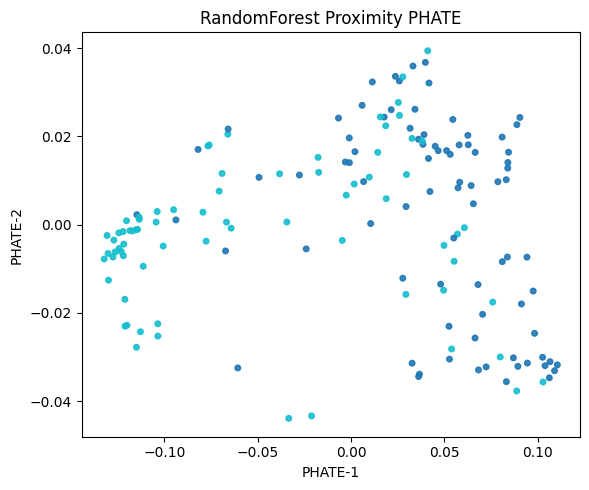

In [5]:
MODEL_MAP = build_model_key_to_class(TASK_TYPE)
results = {}

rf_model, rf_prox = fit_and_get_proximity("RandomForest", MODEL_MAP["RandomForest"], X_train, y_train, TASK_TYPE)
rf_emb = phate_from_proximity(rf_prox, random_state=RANDOM_STATE)
results["RandomForest"] = {"model": rf_model, "proximity": rf_prox, "embedding": rf_emb}

fig, ax = plt.subplots(figsize=(6, 5))
plot_embedding(ax, rf_emb, y_train, "RandomForest Proximity PHATE", TASK_TYPE)
plt.tight_layout()
plt.show()


## 5) ExtraTrees Proximities + PHATE

Calculating PHATE...
  Running PHATE on 156 observations and 156 variables.
  Calculating graph and diffusion operator...
    Calculating PCA...
    Calculating KNN search...
    Calculated KNN search in 0.01 seconds.
    Calculating affinities...
    Calculated affinities in 0.01 seconds.
  Calculated graph and diffusion operator in 0.04 seconds.
  Calculating optimal t...
    Automatically selected t = 20
  Calculated optimal t in 0.02 seconds.
  Calculating diffusion potential...
  Calculating metric MDS...
    SGD-MDS may not have converged: stress changed by -10.6% in final iterations. Consider increasing n_iter or adjusting learning_rate.
  Calculated metric MDS in 0.14 seconds.
Calculated PHATE in 0.20 seconds.


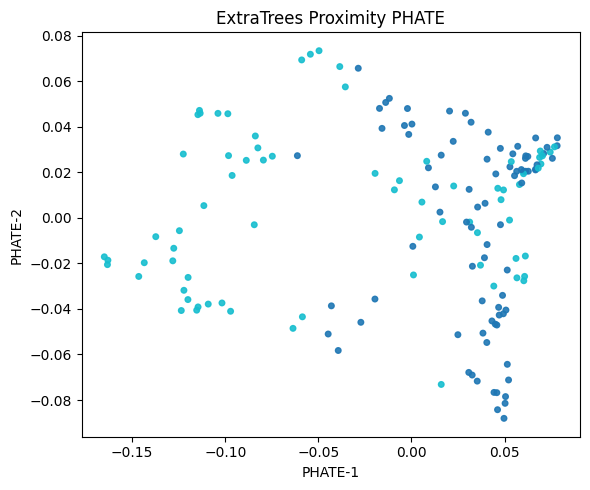

In [6]:
et_model, et_prox = fit_and_get_proximity("ExtraTrees", MODEL_MAP["ExtraTrees"], X_train, y_train, TASK_TYPE)
et_emb = phate_from_proximity(et_prox, random_state=RANDOM_STATE)
results["ExtraTrees"] = {"model": et_model, "proximity": et_prox, "embedding": et_emb}

fig, ax = plt.subplots(figsize=(6, 5))
plot_embedding(ax, et_emb, y_train, "ExtraTrees Proximity PHATE", TASK_TYPE)
plt.tight_layout()
plt.show()


## 6) RotationForest Proximities + PHATE
This section runs only when `aeon` is installed.

Calculating PHATE...
  Running PHATE on 156 observations and 156 variables.
  Calculating graph and diffusion operator...
    Calculating PCA...
    Calculated PCA in 0.01 seconds.
    Calculating KNN search...
    Calculated KNN search in 0.01 seconds.
    Calculating affinities...
  Calculated graph and diffusion operator in 0.03 seconds.
  Calculating optimal t...
    Automatically selected t = 14
  Calculated optimal t in 0.02 seconds.
  Calculating diffusion potential...
  Calculating metric MDS...
    SGD-MDS may not have converged: stress changed by -7.6% in final iterations. Consider increasing n_iter or adjusting learning_rate.
  Calculated metric MDS in 0.14 seconds.
Calculated PHATE in 0.20 seconds.


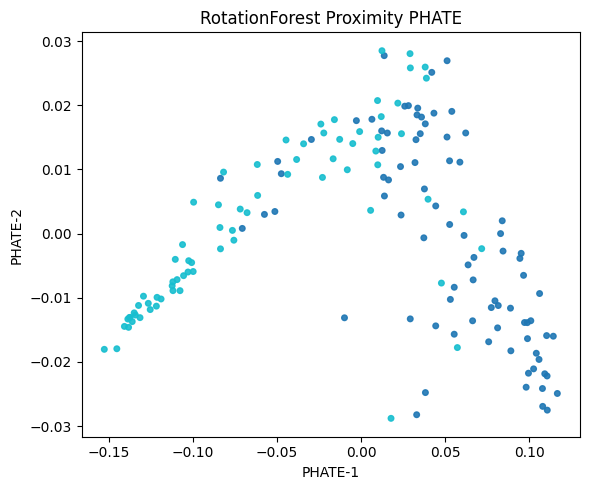

In [7]:
if "RotationForest" in MODEL_MAP:
    rot_model, rot_prox = fit_and_get_proximity("RotationForest", MODEL_MAP["RotationForest"], X_train, y_train, TASK_TYPE)
    rot_emb = phate_from_proximity(rot_prox, random_state=RANDOM_STATE)
    results["RotationForest"] = {"model": rot_model, "proximity": rot_prox, "embedding": rot_emb}

    fig, ax = plt.subplots(figsize=(6, 5))
    plot_embedding(ax, rot_emb, y_train, "RotationForest Proximity PHATE", TASK_TYPE)
    plt.tight_layout()
    plt.show()
else:
    print("Skipping RotationForest section because aeon is not installed.")


## 7) IsolationForest Proximities + PHATE
IsolationForest is unsupervised; we still color points by target values for visual comparison.

Calculating PHATE...
  Running PHATE on 156 observations and 156 variables.
  Calculating graph and diffusion operator...
    Calculating PCA...
    Calculating KNN search...
    Calculating affinities...
  Calculated graph and diffusion operator in 0.03 seconds.
  Calculating optimal t...
    Automatically selected t = 14
  Calculated optimal t in 0.01 seconds.
  Calculating diffusion potential...
  Calculating metric MDS...
    SGD-MDS may not have converged: stress changed by -7.9% in final iterations. Consider increasing n_iter or adjusting learning_rate.
  Calculated metric MDS in 0.13 seconds.
Calculated PHATE in 0.18 seconds.


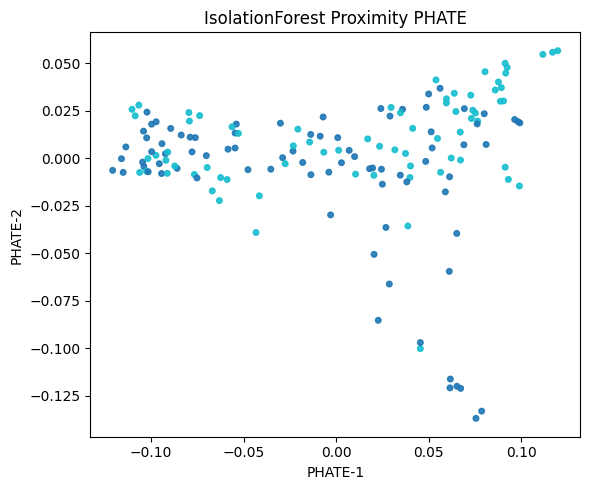

In [8]:
iso_model, iso_prox = fit_and_get_proximity("IsolationForest", MODEL_MAP["IsolationForest"], X_train, y_train, TASK_TYPE)
iso_emb = phate_from_proximity(iso_prox, random_state=RANDOM_STATE)
results["IsolationForest"] = {"model": iso_model, "proximity": iso_prox, "embedding": iso_emb}

fig, ax = plt.subplots(figsize=(6, 5))
plot_embedding(ax, iso_emb, y_train, "IsolationForest Proximity PHATE", TASK_TYPE)
plt.tight_layout()
plt.show()


## 8) ObliqueRandomForest Proximities + PHATE
Oblique splits consider linear combinations of features, enabling more flexible decision boundaries. Requires `treeple`.

In [9]:
if "ObliqueRandomForest" in MODEL_MAP:
    obl_model, obl_prox = fit_and_get_proximity("ObliqueRandomForest", MODEL_MAP["ObliqueRandomForest"], X_train, y_train, TASK_TYPE)
    obl_emb = phate_from_proximity(obl_prox, random_state=RANDOM_STATE)
    results["ObliqueRandomForest"] = {"model": obl_model, "proximity": obl_prox, "embedding": obl_emb}

    fig, ax = plt.subplots(figsize=(6, 5))
    plot_embedding(ax, obl_emb, y_train, "ObliqueRandomForest Proximity PHATE", TASK_TYPE)
    plt.tight_layout()
    plt.show()
else:
    print("Skipping ObliqueRandomForest section because treeple is not installed.")

Skipping ObliqueRandomForest section because treeple is not installed.


## 9) PatchObliqueRandomForest Proximities + PHATE
Patch-oblique trees split on linear combinations within local feature patches. Requires `treeple`.

In [10]:
if "PatchObliqueRandomForest" in MODEL_MAP:
    pobl_model, pobl_prox = fit_and_get_proximity("PatchObliqueRandomForest", MODEL_MAP["PatchObliqueRandomForest"], X_train, y_train, TASK_TYPE)
    pobl_emb = phate_from_proximity(pobl_prox, random_state=RANDOM_STATE)
    results["PatchObliqueRandomForest"] = {"model": pobl_model, "proximity": pobl_prox, "embedding": pobl_emb}

    fig, ax = plt.subplots(figsize=(6, 5))
    plot_embedding(ax, pobl_emb, y_train, "PatchObliqueRandomForest Proximity PHATE", TASK_TYPE)
    plt.tight_layout()
    plt.show()
else:
    print("Skipping PatchObliqueRandomForest section because treeple is not installed.")

Skipping PatchObliqueRandomForest section because treeple is not installed.


## 10) ExtraObliqueRandomForest Proximities + PHATE
Extra-oblique trees add further randomization to the oblique split selection. Requires `treeple`.

In [11]:
if "ExtraObliqueRandomForest" in MODEL_MAP:
    eobl_model, eobl_prox = fit_and_get_proximity("ExtraObliqueRandomForest", MODEL_MAP["ExtraObliqueRandomForest"], X_train, y_train, TASK_TYPE)
    eobl_emb = phate_from_proximity(eobl_prox, random_state=RANDOM_STATE)
    results["ExtraObliqueRandomForest"] = {"model": eobl_model, "proximity": eobl_prox, "embedding": eobl_emb}

    fig, ax = plt.subplots(figsize=(6, 5))
    plot_embedding(ax, eobl_emb, y_train, "ExtraObliqueRandomForest Proximity PHATE", TASK_TYPE)
    plt.tight_layout()
    plt.show()
else:
    print("Skipping ExtraObliqueRandomForest section because treeple is not installed.")

Skipping ExtraObliqueRandomForest section because treeple is not installed.


## 11) HonestForest Proximities + PHATE
Honest forests use separate subsets for structure (splits) and estimation (leaf predictions). Classification only. Requires `treeple`.

In [12]:
if "HonestForest" in MODEL_MAP:
    hf_model, hf_prox = fit_and_get_proximity("HonestForest", MODEL_MAP["HonestForest"], X_train, y_train, TASK_TYPE)
    hf_emb = phate_from_proximity(hf_prox, random_state=RANDOM_STATE)
    results["HonestForest"] = {"model": hf_model, "proximity": hf_prox, "embedding": hf_emb}

    fig, ax = plt.subplots(figsize=(6, 5))
    plot_embedding(ax, hf_emb, y_train, "HonestForest Proximity PHATE", TASK_TYPE)
    plt.tight_layout()
    plt.show()
else:
    print("Skipping HonestForest section (classification only, requires treeple).")

Skipping HonestForest section (classification only, requires treeple).


## 12) UnsupervisedRandomForest Proximities + PHATE
Unsupervised random forest learns structure without labels via synthetic target generation. Requires `treeple`.

In [13]:
if "UnsupervisedRandomForest" in MODEL_MAP:
    urf_model, urf_prox = fit_and_get_proximity("UnsupervisedRandomForest", MODEL_MAP["UnsupervisedRandomForest"], X_train, y_train, TASK_TYPE)
    urf_emb = phate_from_proximity(urf_prox, random_state=RANDOM_STATE)
    results["UnsupervisedRandomForest"] = {"model": urf_model, "proximity": urf_prox, "embedding": urf_emb}

    fig, ax = plt.subplots(figsize=(6, 5))
    plot_embedding(ax, urf_emb, y_train, "UnsupervisedRandomForest Proximity PHATE", TASK_TYPE)
    plt.tight_layout()
    plt.show()
else:
    print("Skipping UnsupervisedRandomForest section because treeple is not installed.")

Skipping UnsupervisedRandomForest section because treeple is not installed.


## 13) UnsupervisedObliqueRandomForest Proximities + PHATE
Unsupervised oblique random forest combines oblique (hyperplane) splits with unsupervised learning via synthetic target generation. Requires `treeple`.

In [14]:
if "UnsupervisedObliqueRandomForest" in MODEL_MAP:
    uorf_model, uorf_prox = fit_and_get_proximity("UnsupervisedObliqueRandomForest", MODEL_MAP["UnsupervisedObliqueRandomForest"], X_train, y_train, TASK_TYPE)
    uorf_emb = phate_from_proximity(uorf_prox, random_state=RANDOM_STATE)
    results["UnsupervisedObliqueRandomForest"] = {"model": uorf_model, "proximity": uorf_prox, "embedding": uorf_emb}

    fig, ax = plt.subplots(figsize=(6, 5))
    plot_embedding(ax, uorf_emb, y_train, "UnsupervisedObliqueRandomForest Proximity PHATE", TASK_TYPE)
    plt.tight_layout()
    plt.show()
else:
    print("Skipping UnsupervisedObliqueRandomForest section because treeple is not installed.")

Skipping UnsupervisedObliqueRandomForest section because treeple is not installed.


## 14) ExtendedIsolationForest Proximities + PHATE
Extended isolation forest uses hyperplane splits instead of axis-aligned ones, improving anomaly detection in multi-dimensional data. Requires `treeple`.

In [15]:
if "ExtendedIsolationForest" in MODEL_MAP:
    eif_model, eif_prox = fit_and_get_proximity("ExtendedIsolationForest", MODEL_MAP["ExtendedIsolationForest"], X_train, y_train, TASK_TYPE)
    eif_emb = phate_from_proximity(eif_prox, random_state=RANDOM_STATE)
    results["ExtendedIsolationForest"] = {"model": eif_model, "proximity": eif_prox, "embedding": eif_emb}

    fig, ax = plt.subplots(figsize=(6, 5))
    plot_embedding(ax, eif_emb, y_train, "ExtendedIsolationForest Proximity PHATE", TASK_TYPE)
    plt.tight_layout()
    plt.show()
else:
    print("Skipping ExtendedIsolationForest section because treeple is not installed.")

Skipping ExtendedIsolationForest section because treeple is not installed.


## 15) Final Comparison: All Forest Proximity PHATE Embeddings
This summary figure compares all available model embeddings in one place.

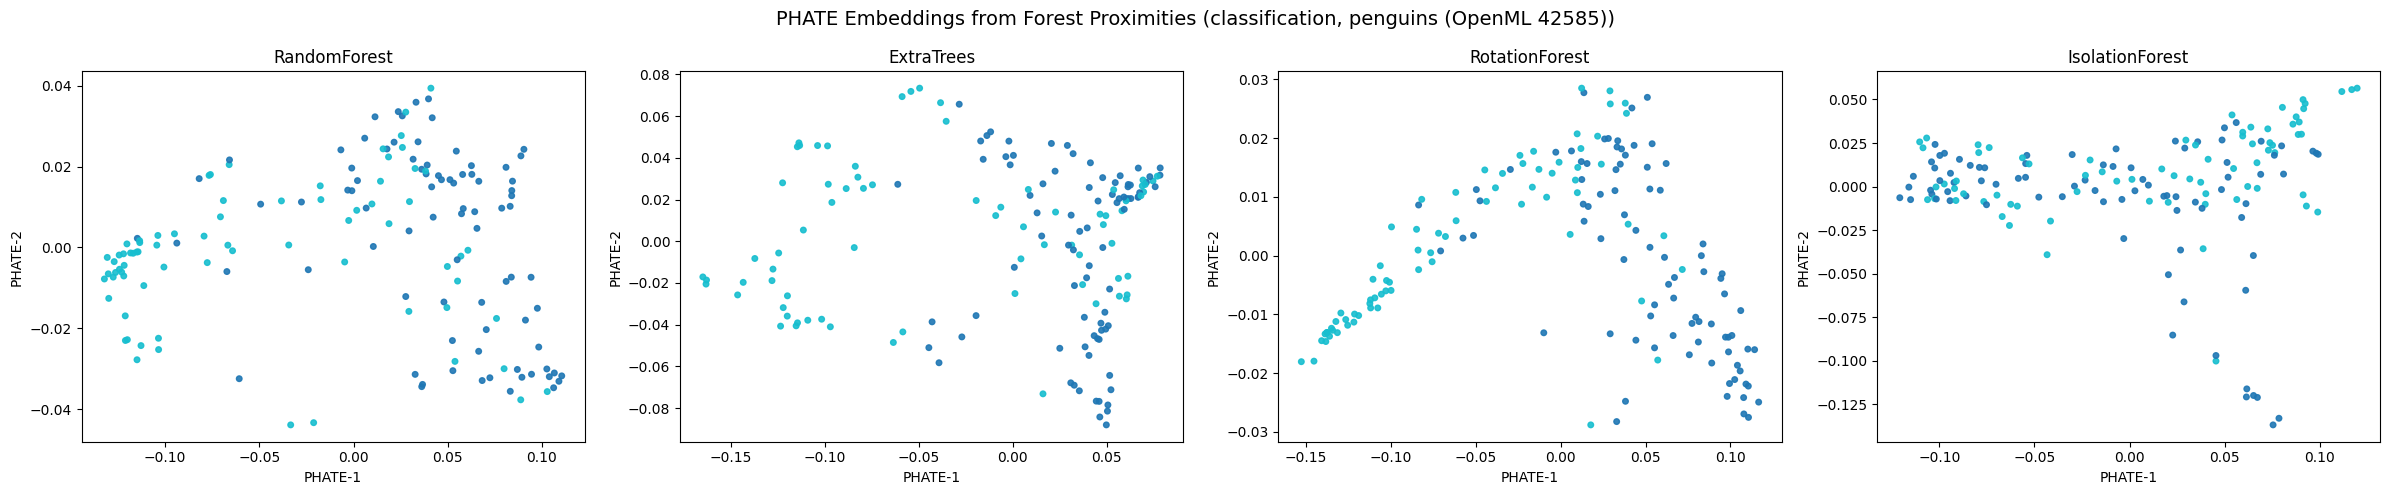

In [16]:
model_order = [
    "RandomForest", "ExtraTrees", "RotationForest", "IsolationForest",
    "ObliqueRandomForest", "PatchObliqueRandomForest", "ExtraObliqueRandomForest",
    "HonestForest", "UnsupervisedRandomForest", "UnsupervisedObliqueRandomForest",
    "ExtendedIsolationForest",
]
available = [m for m in model_order if m in results]
n_models = len(available)

ncols = min(n_models, 4)
nrows = (n_models + ncols - 1) // ncols

fig, axes = plt.subplots(nrows, ncols, figsize=(6 * ncols, 5 * nrows), sharex=False, sharey=False)
axes = np.atleast_1d(axes).ravel()

for i, model_name in enumerate(available):
    ax = axes[i]
    emb = results[model_name]["embedding"]
    plot_embedding(ax, emb, y_train, model_name, TASK_TYPE)

# Hide unused axes
for j in range(n_models, len(axes)):
    axes[j].axis("off")

fig.suptitle(f"PHATE Embeddings from Forest Proximities ({TASK_TYPE}, {dataset_name})", fontsize=14)
plt.tight_layout()
plt.show()